# **Финальный экзамен**
### **Анастасия Филина**

---

Импортируем необходимые библиотеки:

In [1]:
from pathlib import Path
from matplotlib_inline.backend_inline import set_matplotlib_formats
from IPython.display import HTML, display

from rink import plot_rink

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

Включим отображение графиков в формате SVG и зададим единый шрифт (Arial) для графиков и текста отчета в HTML:

In [2]:
set_matplotlib_formats("svg")
plt.rcParams["font.family"] = "Arial"

display(HTML("<style>.jp-RenderedHTMLCommon, .rendered_html {font-family: Arial, sans-serif !important;}</style>"))

Зададим пути к данным и графикам, при необходимости создадим папки для графиков:

In [3]:
DATA_DIR = Path("data")

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

Загрузим данные о событиях матчей. Первый столбец будет как индекс таблицы. Проверим размер данных и посмотрим первые 5 строк:

In [4]:
DATA_PATH = DATA_DIR / "NHL-playoffs-2026.xlsx"
events = pd.read_excel(DATA_PATH, index_col=0)

print(events.shape)
display(events.head())

(29710, 38)


,Dataset,Game ID,Date,Away Team,Home Team,Cumulated Away Score,Cumulated Home Score,Period,Elapsed Time,Remaining Time,...,Away Team's Player on the Ice #6,Away Team's Goalie,Home Team's Player on the Ice #1,Home Team's Player on the Ice #2,Home Team's Player on the Ice #3,Home Team's Player on the Ice #4,Home Team's Player on the Ice #5,Home Team's Player on the Ice #6,Home Team's Goalie,Home Team's Defending Side
0,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:00,20:00,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
1,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:00,20:00,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
2,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:13,19:47,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
3,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:14,19:46,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
4,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:19,19:41,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left


Видим, что Game ID повторяется, т.к. в одном матче может быть много событий

Соберем краткую сводку по каждой игре (дату, названия гостевой и домашней команд, сколько голов забила каждая и сколько овертаймов потребовалось). Для этого оставим по одному событию game-end на игру, возьмем из него итоговый счет и по номеру последнего периода заполним Outcome:

In [5]:
game_ends = events[events["Play Type"] == "game-end"]

game_columns = [
    "Game ID",
    "Date",
    "Away Team",
    "Home Team",
    "Cumulated Away Score",
    "Cumulated Home Score",
    "Period"
]
games = game_ends[game_columns].copy()

games = games.rename(columns={
    "Cumulated Away Score": "Away Score",
    "Cumulated Home Score": "Home Score"
})
games = games.set_index("Game ID")

outcome_by_period = {3: "Final", 4: "Final/OT", 5: "Final/2OT"}
games["Outcome"] = games["Period"].map(outcome_by_period)
games = games.drop(columns="Period")

print(games.shape)
print("Unique Game IDs:", games.index.is_unique)
display(games.head())

(82, 6)
Unique Game IDs: True


,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,Final
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,Final
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,Final
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,Final
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,Final/OT


Получили таблицу из 82 игр. Каждому Game ID соответствует одна строка.

Теперь напишем функцию gameInfo(gameId), которая по идентификатору игры вернет названия команд, итоговый счет, результат и дату. Проверим ее на первой и последней игре:

In [6]:
def gameInfo(gameId):
    game = games.loc[gameId]
    teams = f"{game['Home Team']} - {game['Away Team']}"
    score = f"{game['Home Score']} - {game['Away Score']}"
    details = f"{score}, {game['Outcome']}, {game['Date']}"
    return f"{teams} ({details})"

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


Теперь добавим в games столбец Total Score, т.е. сложим число голов гостевой и домашней команд. Выведем описательные статистики этого показателя:

In [7]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
display(games["Total Score"].describe())

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

Таким образом, в среднем за игру забивали 5,93 шайбы, медиана равна 6. Минимум составил 1 гол, максимум 15 голов

Построим гистограмму числа голов в одной игре. По горизонтали будет число голов, а по вертикали число игр:

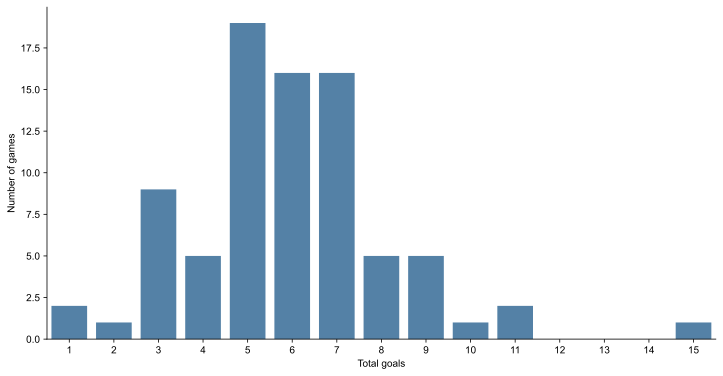

In [8]:
score_order = range(games["Total Score"].min(), games["Total Score"].max() + 1)

plt.figure(figsize=(12, 6))
sns.countplot(data=games, x="Total Score", order=score_order, color="steelblue")
sns.despine()

plt.xlabel("Total goals")
plt.ylabel("Number of games")
plt.savefig(FIGURES_DIR / "total_score.pdf", bbox_inches="tight")
plt.show()

Видим, что чаще всего за матч забивали 5 голов (19 игр). В 61 из 82 игр забили от 4 до 8 голов. 15 голов встретились только в одной игре.

Теперь выведем списки самых нерезультативных и самых результативных игр. Для этого найдем минимальное и максимальное значения Total Score и вызовем gameInfo к каждой подходящей игре:

In [9]:
min_score = games["Total Score"].min()
max_score = games["Total Score"].max()

least_games = games[games["Total Score"] == min_score]
most_games = games[games["Total Score"] == max_score]

print("Least scoring games:")
for game_id in least_games.index:
    print(gameInfo(game_id))

print("Most scoring games:")
for game_id in most_games.index:
    print(gameInfo(game_id))

Least scoring games:
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Most scoring games:
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


Получилось две игры с одним голом и одна игра с 15 голами.

Теперь для каждой игры посчитаем уникальных игроков обеих команд включая вратарей. Возьмем имена из столбцов Player on the Ice, исключим пустые ячейки, найдем игру с макс. числом игроков:

In [10]:
player_columns = []
for number in range(1, 7):
    player_columns.append(f"Away Team's Player on the Ice #{number}")
    player_columns.append(f"Home Team's Player on the Ice #{number}")

player_counts = {}
for game_id, game_events in events.groupby("Game ID"):
    players = set()
    for column in player_columns:
        players.update(game_events[column].dropna())
    player_counts[game_id] = len(players)

games["Player Count"] = pd.Series(player_counts)
max_players = games["Player Count"].max()
most_players = games[games["Player Count"] == max_players]

print("Maximum number of players:", max_players)
for game_id in most_players.index:
    print(gameInfo(game_id))

Maximum number of players: 40
Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)


Получили максимум 40 уникальных игроков в матче от 2026-05-16. Число 41 из примера получается если считать пропуск отдельным значением, а  мы исключили пустые ячейки, т.к. это не игроки

Теперь выберем события shot-on-goal, goal и missed-shot и для каждого вычислим расстояние до ближайшей точки створа ворот. Сторона ворот определяется по стороне защиты хозяев матча и команде, совершившей бросок. Результат добавим в столбец Shot Length:

In [11]:
shot_types = ["shot-on-goal", "goal", "missed-shot"]
shots = events[events["Play Type"].isin(shot_types)].copy()
shot_lengths = []

for _, shot in shots.iterrows():
    if shot["Home Team's Defending Side"] == "left":
        if shot["Team Making the Play"] == shot["Home Team"]:
            goal_x = 89
        else:
            goal_x = -89
    else:
        if shot["Team Making the Play"] == shot["Home Team"]:
            goal_x = -89
        else:
            goal_x = 89

    x = shot["X Coordinate on the Ice Rink"]
    y = shot["Y Coordinate on the Ice Rink"]

    if y < -3:
        length = ((x - goal_x) ** 2 + (y + 3) ** 2) ** 0.5
    elif y > 3:
        length = ((x - goal_x) ** 2 + (y - 3) ** 2) ** 0.5
    else:
        length = abs(x - goal_x)

    shot_lengths.append(length)

shots["Shot Length"] = shot_lengths
events["Shot Length"] = shots["Shot Length"]

display(events.loc[shots.index, ["Game ID", "Play Type", "Shot Length"]].round(3))

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Теперь сравним распределения расстояний для точных (shot-on-goal и goal) и неточных (missed-shot) бросков. Отнормируем каждую гистограмму отдельно, т.к. размеры групп различаются:

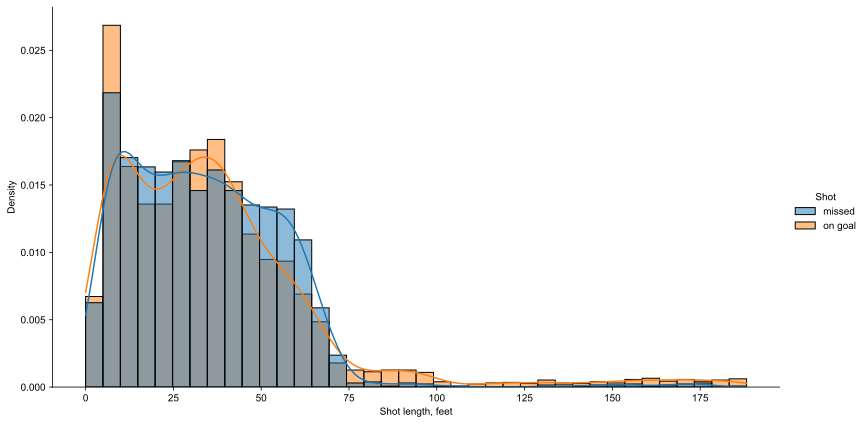

In [12]:
shots["Shot"] = "missed"
shots.loc[shots["Play Type"].isin(["shot-on-goal", "goal"]), "Shot"] = "on goal"

chart = sns.displot(
    data=shots,
    x="Shot Length",
    hue="Shot",
    stat="density",
    common_norm=False,
    binwidth=5,
    height=6,
    aspect=2,
    alpha=0.5,
    kde=True
)

chart.set_axis_labels("Shot length, feet", "Density")
chart.fig.set_size_inches(12, 6)
chart.fig.savefig(FIGURES_DIR / "shot_lengths.pdf", bbox_inches="tight")
plt.show()

В обоих группах основная часть бросков сделана с расстояния до 75 футов. У точных бросков заметен более длинный хвост. Это вероятно потому, что дальние броски из своей зоны доходили до вратаря соперника и учитывались как shot-on-goal.

Теперь для каждой команды в каждой игре рассчитаем долю точных бросков среди всех бросков, кроме заблокированных. Отметим точные броски и найдем среднее значение этой отметки в каждой группе:

In [13]:
shots["On Goal"] = shots["Play Type"].isin(["shot-on-goal", "goal"])

accuracy = shots.groupby(["Game ID", "Team Making the Play"])["On Goal"].mean()

print("Number of game-team pairs:", len(accuracy))
display(accuracy.round(3))
display(accuracy.describe().round(3))

Number of game-team pairs: 164


Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: On Goal, Length: 164, dtype: float64

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: On Goal, dtype: float64

Получили 164 доли, т.е. по одной для каждой пары игра-команда. В среднем доля точных бросков составила 0,639, в отдельных матчах менялась от 0,353 до 0,86. Таким образом точность бросков различается между играми

Теперь усредним доли точных бросков каждой команды по ее матчам и выведем 5 команд с наибольшими и 5 с наименьшими средними значениями:

In [14]:
team_accuracy = accuracy.groupby("Team Making the Play").mean()

print("Highest average shares:")
display(team_accuracy.nlargest(5).round(3))

print("Lowest average shares:")
display(team_accuracy.nsmallest(5).round(3))

Highest average shares:


Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: On Goal, dtype: float64

Lowest average shares:


Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: On Goal, dtype: float64

Наибольшую среднюю долю точных бросков получил Edmonton Oilers (0,706), а наименьшую Pittsburgh Penguins (0,554). Разница составляет 0,152

Теперь для каждой команды посчитаем среднее за матч число бросков в створ и число голов. Броски в створ включают события shot-on-goal и goal. Голы посчитаем также отдельно:

In [15]:
shots["Goal"] = shots["Play Type"] == "goal"

shot_counts = shots.groupby(["Game ID", "Team Making the Play"])[["On Goal", "Goal"]].sum()
avgshots = shot_counts.groupby("Team Making the Play").mean()
avgshots = avgshots.rename(columns={"On Goal": "Shot"})

display(avgshots.round(3))

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


Получили среднее число бросков в створ и голов за матч для 16 команд.

Теперь построим диаграмму рассеяния с линией регрессии и посмотрим, связаны ли эти показатели:

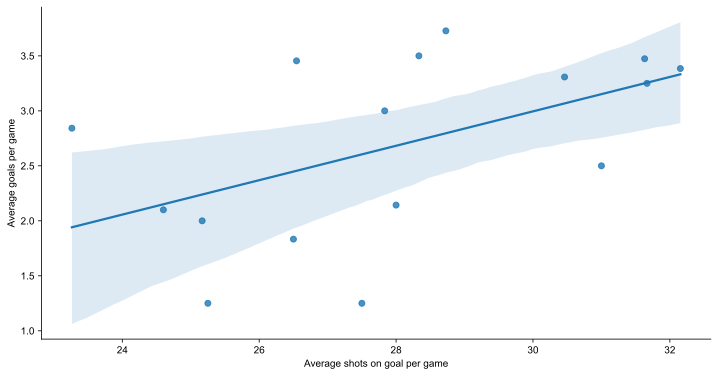

In [16]:
plt.figure(figsize=(12, 6))
sns.regplot(data=avgshots, x="Shot", y="Goal")
sns.despine()

plt.xlabel("Average shots on goal per game")
plt.ylabel("Average goals per game")
plt.savefig(FIGURES_DIR / "shots_and_goals.pdf", bbox_inches="tight")
plt.show()

На диаграмме видим положительную связь между средним числом бросков в створ и голов, но точки заметно разбросаны вокруг линии

Теперь найдем матч с наибольшим общим числом попыток броска обеих команд. Учтем голы, броски в створ, мимо ворот и заблокированные броски:

In [17]:
attempt_types = ["goal", "shot-on-goal", "missed-shot", "blocked-shot"]
attempts = events[events["Play Type"].isin(attempt_types)].copy()
attempt_counts = attempts.groupby("Game ID").size()

max_attempts = attempt_counts.max()
max_games = attempt_counts[attempt_counts == max_attempts]

print("Maximum number of shot attempts:", max_attempts)
for game_id in max_games.index:
    print(gameInfo(game_id))

Maximum number of shot attempts: 208
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


Получили максимум 208 попыток броска в матче Carolina Hurricanes - Ottawa Senators

Теперь покажем их на схеме площадки. Тип события обозначается цветом, а направление стрелки обозначает команду (Carolina Hurricanes направо, Ottawa Senators налево)

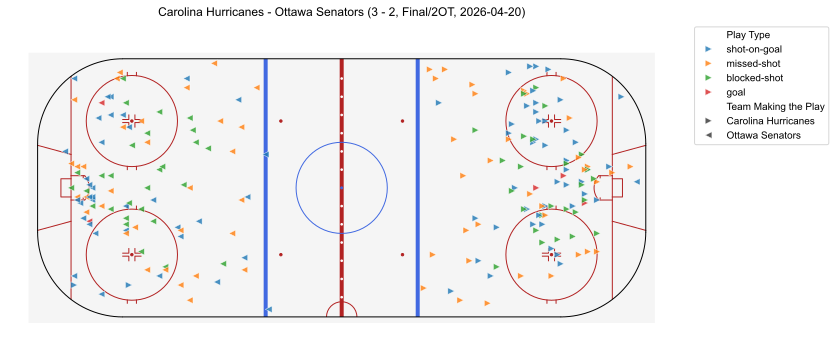

In [18]:
max_game_id = max_games.index[0]
game_shots = attempts[attempts["Game ID"] == max_game_id].copy()

game_shots["Plot X"] = game_shots["X Coordinate on the Ice Rink"]
game_shots["Plot Y"] = game_shots["Y Coordinate on the Ice Rink"]

odd_periods = game_shots["Period"] % 2 == 1
game_shots.loc[odd_periods, "Plot X"] *= -1
game_shots.loc[odd_periods, "Plot Y"] *= -1

plt.figure(figsize=(12, 6))
plot_rink()
sns.scatterplot(
    data=game_shots,
    x="Plot X",
    y="Plot Y",
    hue="Play Type",
    style="Team Making the Play",
    markers={"Carolina Hurricanes": ">", "Ottawa Senators": "<"},
    s=45,
    alpha=0.8
)

plt.axis("equal")
plt.axis("off")
plt.title(gameInfo(max_game_id))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig(FIGURES_DIR / "game_shots.pdf", bbox_inches="tight")
plt.show()

Carolina Hurricanes атакуют вправо, Ottawa Senators влево

Теперь найдем 10 игроков, забивших больше всего голов в плей-офф:

In [19]:
goals = events[events["Play Type"] == "goal"]
goal_counts = goals["Player in the Event #1"].value_counts()

display(goal_counts.head(10))

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: count, dtype: int64

Больше всего голов (14) забил Brett Howden

Теперь объединим авторов 1-й и 2-й голевых передач и выведем 10 игроков с наибольшим числом передач:

In [20]:
first_assists = goals["Player in the Event #2"]
second_assists = goals["Player in the Event #3"]

assist_names = pd.concat([first_assists, second_assists], ignore_index=True)
assist_counts = assist_names.value_counts()

display(assist_counts.head(10))

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

Больше всего (20) сделал Jack Eichel

Теперь для каждого игрока сложим голы и передачи и выведем 10 лидеров по очкам:

In [21]:
points = goal_counts.add(assist_counts, fill_value=0).astype(int)
points = points.sort_values(ascending=False)

display(points.head(10))

Player in the Event #1
Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Brett Howden       18
Nikolaj Ehlers     18
Shea Theodore      18
Pavel Dorofeyev    16
Lane Hutson        16
Logan Stankoven    16
Name: count, dtype: int64

Больше всего очков (29) по системе гол+пас набрал Mitch Marner

Теперь найдем 10 игроков с наибольшим средним числом бросков в створ за игру. Число игр определим по присутствию игрока на льду. Бросками в створ считаем shot-on-goal и goal:

In [22]:
player_games = {}

for game_id, game_events in events.groupby("Game ID"):
    players = set()
    for column in player_columns:
        players.update(game_events[column].dropna())

    for player in players:
        player_games[player] = player_games.get(player, 0) + 1

games_played = pd.Series(player_games)

shot_events = events[events["Play Type"].isin(["shot-on-goal", "goal"])]
shot_counts_by_player = shot_events["Player in the Event #1"].value_counts()
shots_per_game = (shot_counts_by_player / games_played).sort_values(ascending=False)

display(shots_per_game.head(10).round(3))

Player in the Event #1
Jason Robertson     5.000
Dylan Guenther      4.500
Nikita Kucherov     4.429
Matt Boldy          4.364
Quinton Byfield     4.250
Darren Raddysh      4.000
Joel Eriksson Ek    4.000
Alex Laferriere     3.750
David Pastrnak      3.667
Nathan MacKinnon    3.615
dtype: float64

Лидером по среднему числу бросков (5 за матч) в створ стал Jason Robertson

Теперь таким же способом посчитаем среднее число силовых приемов за игру по событиям hit:

In [23]:
hits = events[events["Play Type"] == "hit"]
hit_counts_by_player = hits["Player in the Event #1"].value_counts()
hits_per_game = (hit_counts_by_player / games_played).sort_values(ascending=False)

display(hits_per_game.head(10).round(3))

Player in the Event #1
Lawson Crouse         6.333
Alex Turcotte         6.000
Alexander Petrovic    6.000
Yakov Trenin          5.667
Dylan Cozens          5.500
Vasily Podkolzin      5.333
Marcus Foligno        5.000
Ivan Barbashev        5.000
Carl Grundstrom       5.000
Owen Tippett          4.833
dtype: float64

Больше всего силовых приемов (6,333 за игру) в среднем совершил Lawson Crouse

Теперь найдем вратарей, которые хотя бы в одном матче не пропустили ни одной шайбы. Нужно учесть и тех кто провел только часть матча

In [24]:
shutout_goalies = set()

for game_id, game_events in events.groupby("Game ID"):
    game_goals = game_events[game_events["Play Type"] == "goal"].copy()
    goalie_columns = ["Away Team's Goalie", "Home Team's Goalie"]
    missing_goalies = game_goals[goalie_columns].isna().all(axis=1)
    overtime_goals = game_goals["Period"] > 3
    goal_ids = game_goals.index[missing_goalies & overtime_goals]

    previous_goalies = game_events[goalie_columns].shift(1)
    game_goals.loc[goal_ids, goalie_columns] = previous_goalies.loc[goal_ids]

    for team_column, goalie_column in [
        ("Away Team", "Away Team's Goalie"),
        ("Home Team", "Home Team's Goalie")
    ]:
        team = game_events[team_column].iloc[0]
        opponent_goals = game_goals[game_goals["Team Making the Play"] != team]

        for goalie in game_events[goalie_column].dropna().unique():
            goals_allowed = opponent_goals[opponent_goals[goalie_column] == goalie]
            if goals_allowed.empty:
                shutout_goalies.add(goalie)

print("Number of goalies:", len(shutout_goalies))
for goalie in sorted(shutout_goalies):
    print(goalie)

Number of goalies: 6
Andrei Vasilevskiy
Brandon Bussi
Dan Vladar
Frederik Andersen
Joonas Korpisalo
Scott Wedgewood


Получили список из 6 вратарей, которые хотя бы в одном матче не пропустили ни одной шайбы, пока находились на льду

Содержательный вопрос: "Как различалась доля побед хозяев в матчах с овертаймом и без него?"

Чтобы ответить на него, для обеих групп посчитаем число матчей, побед хозяев и долю побед:

In [25]:
games["Home Win"] = games["Home Score"] > games["Away Score"]
games["Overtime"] = games["Outcome"] != "Final"

home_wins = games.groupby("Overtime")["Home Win"].agg(["sum", "count", "mean"])
display(home_wins.round(3))

,sum,count,mean
Overtime,,,
False,25,60,0.417
True,14,22,0.636


Без овертайма хозяева выиграли 25 из 60 матчей (41,7%), а с овертаймом 14 из 22 (63,6%). В этих данных доля побед хозяев среди матчей с овертаймом выше

Это сравнение описывает конкретно эту выборку и не доказывает, что именно овертайм вызвал различие в доле побед хозяев